# Graph Attention Network (GAT) — Elliptic Bitcoin Fraud Detection

This notebook trains and evaluates a two-layer Graph Attention Network on the same preprocessed Elliptic graph and temporal masks used by the GCN and GraphSAGE baselines.

- Label 0: legitimate; label 1: illicit/fraud; label -1: unknown and excluded from supervised masks.
- Full-graph transductive training is used for a consistent comparison with the existing baselines.
- The model is selected using **validation fraud F1**; the test split is evaluated only after restoring the best checkpoint.
- GAT uses four attention heads in the first layer (16 channels per head, 64 combined features) and one output head.
- The current Streamlit dashboard remains GCN-specific; this notebook does not change the app.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch_geometric.nn import GATConv

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

C:\Users\nakul\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


## 2. Resolve project paths and load the existing graph

In [2]:
# Supports running Jupyter with either the repository root or model/ as the working directory.
cwd = Path.cwd().resolve()
if (cwd / "data" / "processed").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "processed").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not locate data/processed from the current working directory: "
        f"{cwd}. Run this notebook from the repository root or model/."
    )

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "model"
GRAPH_PATH = DATA_DIR / "elliptic_graph.pt"
CLASS_WEIGHTS_PATH = DATA_DIR / "class_weights.pt"
CHECKPOINT_PATH = MODEL_DIR / "best_gat_model.pt"
METRICS_PATH = MODEL_DIR / "gat_metrics.json"
RESULTS_DIR = PROJECT_ROOT / "results" / "GAT"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for required_path in (GRAPH_PATH, CLASS_WEIGHTS_PATH):
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required file not found: {required_path}\n"
            "Run notebooks/elliptic_preprocessing.ipynb locally first. "
            "Processed graph files are intentionally not stored in Git."
        )

graph_data = torch.load(GRAPH_PATH, map_location="cpu", weights_only=False)
print(graph_data)
print("Features:", tuple(graph_data.x.shape))
print("Edges:", tuple(graph_data.edge_index.shape))
print("Train nodes:", int(graph_data.train_mask.sum()))
print("Validation nodes:", int(graph_data.val_mask.sum()))
print("Test nodes:", int(graph_data.test_mask.sum()))
print("Unique labels:", torch.unique(graph_data.y).tolist())

Data(x=[203769, 165], edge_index=[2, 468710], y=[203769], train_mask=[203769], val_mask=[203769], test_mask=[203769])
Features: (203769, 165)
Edges: (2, 468710)
Train nodes: 29894
Validation nodes: 7829
Test nodes: 8841
Unique labels: [-1, 0, 1]


## 3. Validate masks and labels

In [3]:
# Every supervised mask should contain only known binary labels.
for split_name in ("train", "val", "test"):
    mask = getattr(graph_data, f"{split_name}_mask")
    labels = graph_data.y[mask]
    assert mask.dtype == torch.bool
    assert labels.numel() > 0, f"{split_name} mask is empty"
    assert bool(torch.all((labels == 0) | (labels == 1))), (
        f"{split_name} mask includes labels outside {{0, 1}}"
    )

train_labels = graph_data.y[graph_data.train_mask]
print("Training class counts:", torch.bincount(train_labels, minlength=2).tolist())
print("All supervised masks exclude unknown label -1.")

Training class counts: [26432, 3462]
All supervised masks exclude unknown label -1.


## 4. Define the two-layer GAT model

In [4]:
class GAT(torch.nn.Module):
    def __init__(
        self,
        num_features,
        hidden_channels=16,
        num_heads=4,
        num_classes=2,
        feature_dropout=0.5,
        attention_dropout=0.5,
    ):
        super().__init__()
        self.feature_dropout = feature_dropout
        self.conv1 = GATConv(
            num_features,
            hidden_channels,
            heads=num_heads,
            concat=True,
            dropout=attention_dropout,
        )
        self.conv2 = GATConv(
            hidden_channels * num_heads,
            num_classes,
            heads=1,
            concat=False,
            dropout=attention_dropout,
        )

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.feature_dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.feature_dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x  # raw logits for CrossEntropyLoss

# First layer outputs 4 heads x 16 channels = 64 features, matching the baseline hidden width.
num_features = graph_data.num_node_features
hidden_channels = 16
num_heads = 4
num_classes = 2
feature_dropout = 0.5
attention_dropout = 0.5

model = GAT(
    num_features=num_features,
    hidden_channels=hidden_channels,
    num_heads=num_heads,
    num_classes=num_classes,
    feature_dropout=feature_dropout,
    attention_dropout=attention_dropout,
).to(device)

graph_data = graph_data.to(device)
class_weights = torch.load(
    CLASS_WEIGHTS_PATH,
    map_location=device,
    weights_only=True,
).float()
assert class_weights.numel() == num_classes

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4,
)

print(model)
print("Class weights:", class_weights.detach().cpu().tolist())
print("Attention heads:", num_heads, "| channels per head:", hidden_channels)

GAT(
  (conv1): GATConv(165, 16, heads=4)
  (conv2): GATConv(64, 2, heads=1)
)
Class weights: [0.5654888153076172, 4.317446708679199]
Attention heads: 4 | channels per head: 16


## 5. Training and validation helpers

In [5]:
@torch.no_grad()
def predict_all():
    model.eval()
    return model(graph_data.x, graph_data.edge_index)

@torch.no_grad()
def evaluate(mask, logits=None):
    if logits is None:
        logits = predict_all()

    y_true = graph_data.y[mask].detach().cpu().numpy()
    split_logits = logits[mask]
    y_pred = split_logits.argmax(dim=1).detach().cpu().numpy()
    fraud_probs = torch.softmax(split_logits, dim=1)[:, 1].detach().cpu().numpy()

    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "fraud_precision": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "fraud_recall": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "fraud_f1": float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "pr_auc_average_precision": float(average_precision_score(y_true, fraud_probs)),
    }
    metrics["roc_auc"] = (
        float(roc_auc_score(y_true, fraud_probs))
        if np.unique(y_true).size == 2
        else None
    )
    return metrics

def train_one_epoch():
    model.train()
    optimizer.zero_grad()
    logits = model(graph_data.x, graph_data.edge_index)
    loss = criterion(
        logits[graph_data.train_mask],
        graph_data.y[graph_data.train_mask],
    )
    loss.backward()
    optimizer.step()
    return float(loss.item())

## 6. Train and select the checkpoint using validation fraud F1

In [6]:
NUM_EPOCHS = 100
best_val_f1 = -1.0
train_losses = []
val_f1_scores = []
val_pr_auc_scores = []

MODEL_DIR.mkdir(parents=True, exist_ok=True)

for epoch in range(1, NUM_EPOCHS + 1):
    loss = train_one_epoch()
    logits = predict_all()
    val_metrics = evaluate(graph_data.val_mask, logits=logits)

    train_losses.append(loss)
    val_f1_scores.append(val_metrics["fraud_f1"])
    val_pr_auc_scores.append(val_metrics["pr_auc_average_precision"])

    # Use the same validation-F1 checkpoint rule as GCN and GraphSAGE.
    if val_metrics["fraud_f1"] > best_val_f1:
        best_val_f1 = val_metrics["fraud_f1"]
        torch.save(model.state_dict(), CHECKPOINT_PATH)

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | Loss {loss:.4f} | "
            f"Val Precision {val_metrics['fraud_precision']:.4f} | "
            f"Val Recall {val_metrics['fraud_recall']:.4f} | "
            f"Val F1 {val_metrics['fraud_f1']:.4f} | "
            f"Val PR-AUC {val_metrics['pr_auc_average_precision']:.4f}"
        )

print(f"Best validation fraud F1: {best_val_f1:.4f}")
print("Checkpoint saved to:", CHECKPOINT_PATH)

Epoch 001 | Loss 2.1023 | Val Precision 0.1251 | Val Recall 0.9037 | Val F1 0.2198 | Val PR-AUC 0.2423
Epoch 010 | Loss 0.6457 | Val Precision 0.1962 | Val Recall 0.7926 | Val F1 0.3145 | Val PR-AUC 0.2849
Epoch 020 | Loss 0.4751 | Val Precision 0.1737 | Val Recall 0.9511 | Val F1 0.2938 | Val PR-AUC 0.5519
Epoch 030 | Loss 0.4609 | Val Precision 0.1886 | Val Recall 0.8933 | Val F1 0.3114 | Val PR-AUC 0.4140
Epoch 040 | Loss 0.4254 | Val Precision 0.1991 | Val Recall 0.8948 | Val F1 0.3257 | Val PR-AUC 0.4988
Epoch 050 | Loss 0.4130 | Val Precision 0.2076 | Val Recall 0.8607 | Val F1 0.3346 | Val PR-AUC 0.4717
Epoch 060 | Loss 0.4047 | Val Precision 0.2080 | Val Recall 0.8622 | Val F1 0.3352 | Val PR-AUC 0.5093
Epoch 070 | Loss 0.3957 | Val Precision 0.2140 | Val Recall 0.8533 | Val F1 0.3422 | Val PR-AUC 0.4408
Epoch 080 | Loss 0.3901 | Val Precision 0.2314 | Val Recall 0.8326 | Val F1 0.3621 | Val PR-AUC 0.4330
Epoch 090 | Loss 0.3846 | Val Precision 0.2232 | Val Recall 0.8593 | Val 

## 7. Restore the best checkpoint and evaluate the test split

In [7]:
# Only the validation-selected checkpoint is used for final test evaluation.
best_state = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(best_state)
model.eval()

test_logits = predict_all()
test_metrics = evaluate(graph_data.test_mask, logits=test_logits)

y_test = graph_data.y[graph_data.test_mask].detach().cpu().numpy()
test_predictions = test_logits[graph_data.test_mask].argmax(dim=1).detach().cpu().numpy()
test_probabilities = (
    torch.softmax(test_logits[graph_data.test_mask], dim=1)[:, 1]
    .detach().cpu().numpy()
)

print("Final test metrics:")
print(json.dumps(test_metrics, indent=2))
print("\nClassification report (0 = Legitimate, 1 = Fraud):")
print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["Legitimate", "Fraud"],
        zero_division=0,
        digits=4,
    )
)

Final test metrics:
{
  "accuracy": 0.7468612147947065,
  "fraud_precision": 0.10930828351836037,
  "fraud_recall": 0.6274509803921569,
  "fraud_f1": 0.18618181818181817,
  "pr_auc_average_precision": 0.3094230720917584,
  "roc_auc": 0.8073302130053965
}

Classification report (0 = Legitimate, 1 = Fraud):
              precision    recall  f1-score   support

  Legitimate     0.9766    0.7526    0.8501      8433
       Fraud     0.1093    0.6275    0.1862       408

    accuracy                         0.7469      8841
   macro avg     0.5430    0.6900    0.5182      8841
weighted avg     0.9366    0.7469    0.8195      8841



## 8. Save confusion matrix and training/validation curves

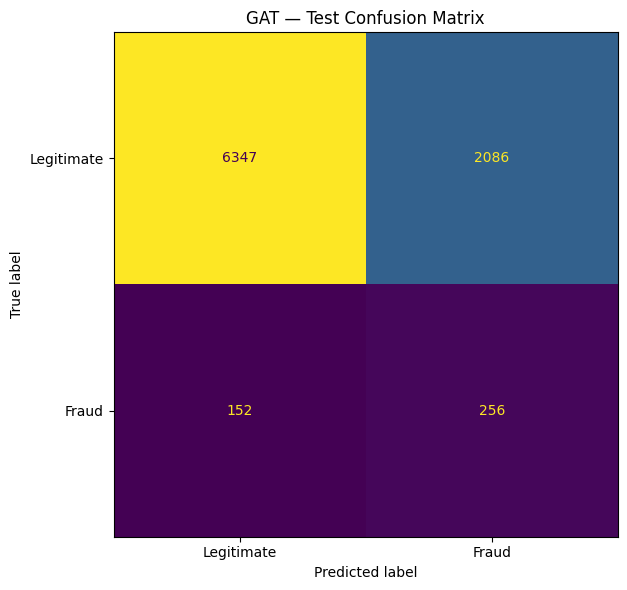

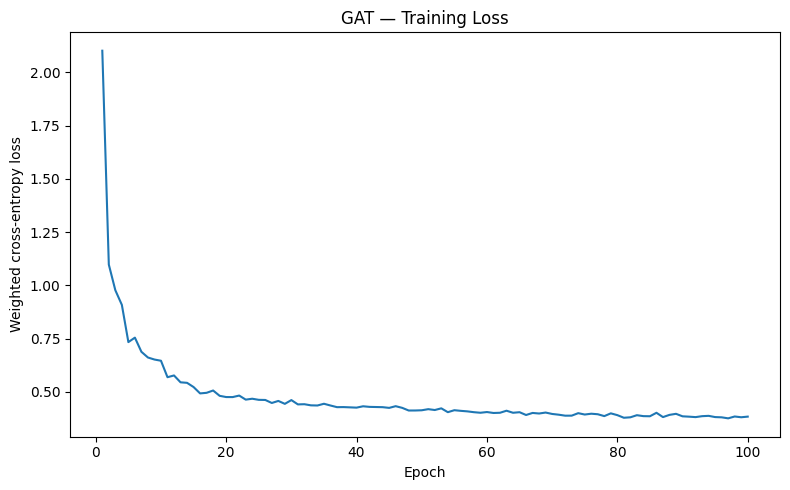

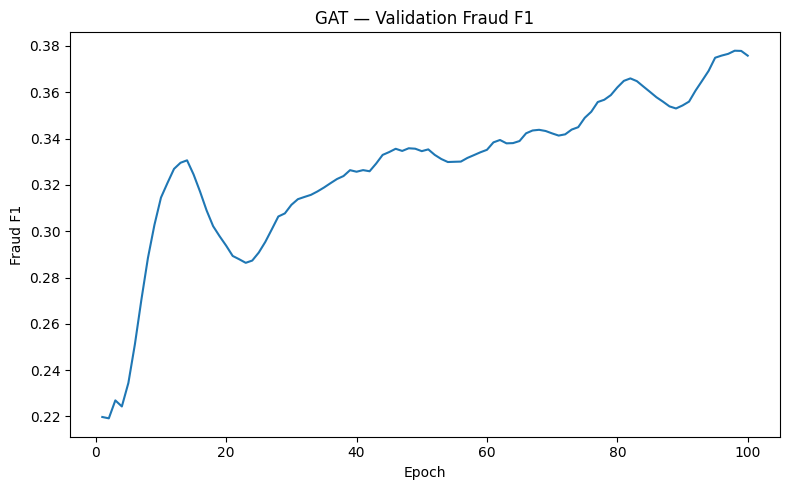

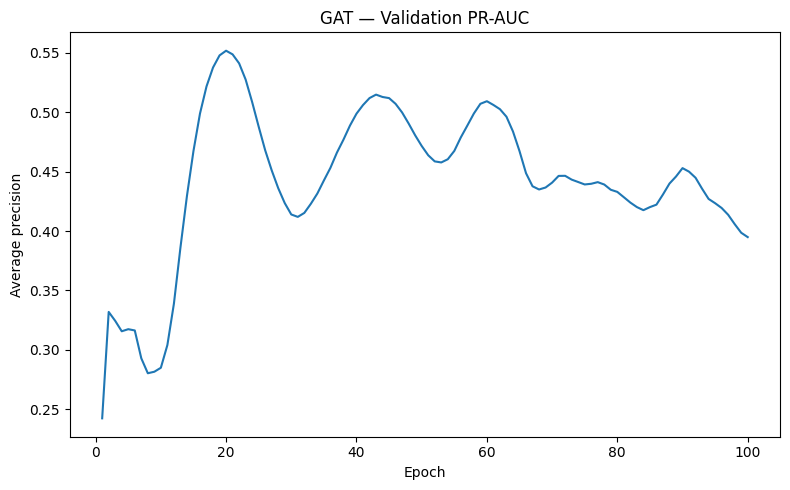

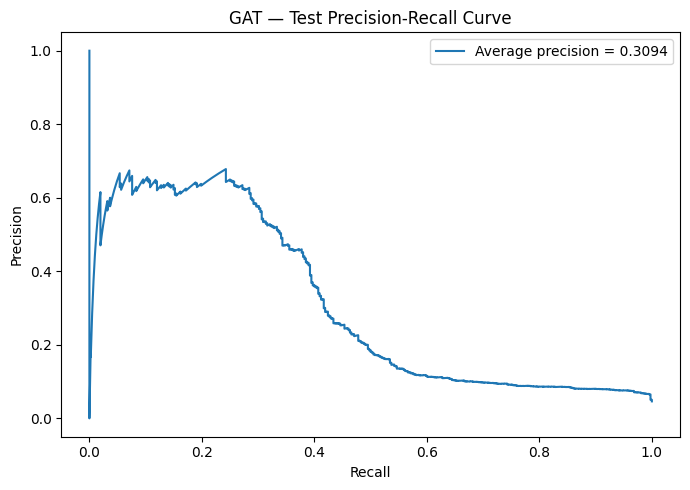

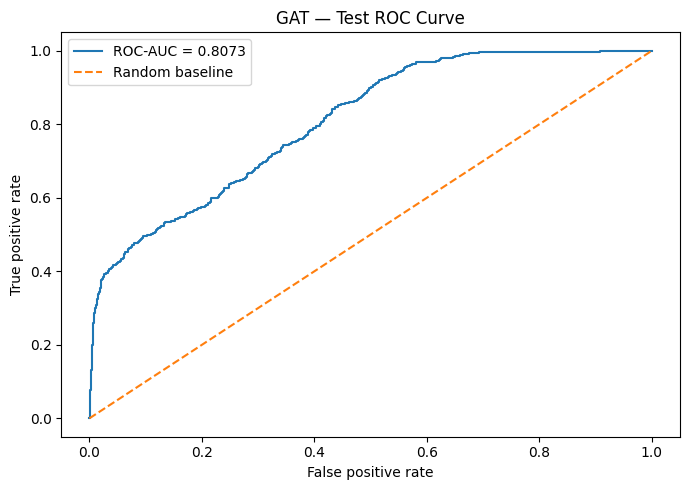

Saved GAT figures to: C:\Users\nakul\Desktop\Explainable Financial Fraud Detection\results\GAT


In [8]:
# All figures are written to results/GAT/.
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Legitimate", "Fraud"])
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("GAT — Test Confusion Matrix")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(train_losses) + 1), train_losses)
ax.set_title("GAT — Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted cross-entropy loss")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_loss.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(val_f1_scores) + 1), val_f1_scores)
ax.set_title("GAT — Validation Fraud F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("Fraud F1")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "validation_f1.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(val_pr_auc_scores) + 1), val_pr_auc_scores)
ax.set_title("GAT — Validation PR-AUC")
ax.set_xlabel("Epoch")
ax.set_ylabel("Average precision")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "validation_pr_auc.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Test curves use predicted probabilities rather than hard class predictions.
pr_precision, pr_recall, _ = precision_recall_curve(y_test, test_probabilities)
pr_auc_value = average_precision_score(y_test, test_probabilities)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pr_recall, pr_precision, label=f"Average precision = {pr_auc_value:.4f}")
ax.set_title("GAT — Test Precision-Recall Curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

roc_fpr, roc_tpr, _ = roc_curve(y_test, test_probabilities)
roc_auc_value = roc_auc_score(y_test, test_probabilities)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(roc_fpr, roc_tpr, label=f"ROC-AUC = {roc_auc_value:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("GAT — Test ROC Curve")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved GAT figures to:", RESULTS_DIR)

## 9. Save metrics for cross-model comparison

In [9]:
metrics_payload = {
    "model": "GAT",
    "dataset": "Elliptic Bitcoin",
    "seed": SEED,
    "architecture": {
        "layers": 2,
        "hidden_channels_per_head": hidden_channels,
        "attention_heads_first_layer": num_heads,
        "output_heads": 1,
        "feature_dropout": feature_dropout,
        "attention_dropout": attention_dropout,
        "first_layer_output_channels": hidden_channels * num_heads,
    },
    "training": {
        "epochs": NUM_EPOCHS,
        "learning_rate": 0.01,
        "weight_decay": 5e-4,
        "checkpoint_selection": "best validation fraud F1",
        "best_validation_fraud_f1": float(best_val_f1),
    },
    "test_metrics": test_metrics,
    "split_sizes": {
        "train": int(graph_data.train_mask.sum().item()),
        "validation": int(graph_data.val_mask.sum().item()),
        "test": int(graph_data.test_mask.sum().item()),
    },
}

with METRICS_PATH.open("w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

with (RESULTS_DIR / "metrics.json").open("w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)
pd.DataFrame([test_metrics]).to_csv(RESULTS_DIR / "metrics.csv", index=False)

print("Metrics saved to:", METRICS_PATH)
print("Results directory:", RESULTS_DIR)
print("Checkpoint:", CHECKPOINT_PATH)
print("\nCompare models using the same graph artifact, temporal masks, and metric definitions.")

Metrics saved to: C:\Users\nakul\Desktop\Explainable Financial Fraud Detection\model\gat_metrics.json
Results directory: C:\Users\nakul\Desktop\Explainable Financial Fraud Detection\results\GAT
Checkpoint: C:\Users\nakul\Desktop\Explainable Financial Fraud Detection\model\best_gat_model.pt

Compare models using the same graph artifact, temporal masks, and metric definitions.


## Notes for the comparison

- GAT uses attention-weighted neighbor aggregation, while GCN uses graph convolution and GraphSAGE uses mean aggregation.
- Compare fraud precision, recall, F1, PR-AUC (average precision), ROC-AUC, and the confusion matrix. Accuracy alone is insufficient for this imbalanced dataset.
- GAT's checkpoint is saved separately as model/best_gat_model.pt; it does not overwrite either baseline checkpoint.
- Full-graph attention can be slower and use more memory than GCN/GraphSAGE. If an out-of-memory error occurs, reduce num_heads or hidden_channels consistently and record that change in the experiment metadata.
- The current Streamlit loader and explainer remain GCN-specific. Do not connect this checkpoint to the dashboard until model-loading and explanation support are deliberately generalized and tested.